![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 03 | Evaluation and Interpretation

*Project 2 — Machine Learning: From Data to Predictions*

**Alex Russell**  
**Dataset:** IBM Telco Customer Churn

This notebook evaluates the final model once on the untouched test set, analyses its mistakes, explains what drives its predictions, saves and reloads the fitted pipeline, and finishes with an operational recommendation and clear limits on how the model should be used.

---
## 0. Setup

In [1]:
import sys
sys.path.append("..")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.functions import (
    MODELS,
    RANDOM_STATE,
    build_preprocessor,
    load_and_split_data,
)

pd.set_option("display.max_columns", 100)

---
## 1. The question and the final model

The aim is to predict which telecom customers are likely to churn so that a retention team can prioritise customers for intervention before they leave.
The positive class is Churn = Yes. Recall was chosen as the main metric because failing to identify a genuine churner means losing the opportunity to retain them.
After comparing Logistic Regression, Decision Tree and Random Forest models using the same cross-validation folds, tuned Logistic Regression performed best. The final model uses C=1 and class_weight='balanced', with a classification threshold of 0.50. Its cross-validated recall was approximately 0.801.

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Recreate exactly the same train/test split
X_train, X_test, y_train, y_test = load_and_split_data()

# Same feature groups as notebook 02
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

# Same preprocessing
preprocessor = build_preprocessor(
    numeric_features,
    categorical_features
)

# Final tuned model
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        C=1,
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

final_threshold = 0.50

# Re-check the expected training-only spread for the chosen model.
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import make_scorer, recall_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

recall_scorer = make_scorer(
    recall_score,
    pos_label="Yes"
)

final_cv_scores = cross_val_score(
    final_model,
    X_train,
    y_train,
    cv=cv,
    scoring=recall_scorer
)

cv_recall = final_cv_scores.mean()
cv_recall_std = final_cv_scores.std()

# Fit on ALL training data only after model and threshold are fixed.
final_model.fit(X_train, y_train)

print("Final model fitted.")
print("Training rows:", X_train.shape[0])
print("Final threshold:", final_threshold)
print(f"CV recall: {cv_recall:.3f} ± {cv_recall_std:.3f}")

Final model fitted.
Training rows: 5634
Final threshold: 0.5
CV recall: 0.801 ± 0.038


---
## 2. Final test evaluation

In [3]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score)

# Get churn probabilities for the untouched test set
test_probabilities = final_model.predict_proba(X_test)

# Find the probability column for Churn = Yes
yes_index = list(
    final_model.named_steps["model"].classes_
).index("Yes")

churn_probabilities = test_probabilities[:, yes_index]

# Apply our chosen threshold
test_predictions = np.where(
    churn_probabilities >= final_threshold,
    "Yes",
    "No"
)

# Final test metrics
test_accuracy = accuracy_score(y_test, test_predictions)

test_precision = precision_score(
    y_test,
    test_predictions,
    pos_label="Yes"
)

test_recall = recall_score(
    y_test,
    test_predictions,
    pos_label="Yes"
)

test_f1 = f1_score(
    y_test,
    test_predictions,
    pos_label="Yes"
)

# Previous training-only benchmark
baseline_recall = 0.0

print("FINAL TEST RESULTS")
print("------------------")
print(f"Accuracy:  {test_accuracy:.3f}")
print(f"Precision: {test_precision:.3f}")
print(f"Recall:    {test_recall:.3f}")
print(f"F1:        {test_f1:.3f}")

print("\nCOMPARISON")
print("------------------")
print(f"Dummy baseline recall:     {baseline_recall:.3f}")
print(f"Cross-validated recall:    {cv_recall:.3f} ± {cv_recall_std:.3f}")
print(f"Final test recall:         {test_recall:.3f}")
print(f"Difference from CV estimate: {test_recall - cv_recall:+.3f}")

FINAL TEST RESULTS
------------------
Accuracy:  0.738
Precision: 0.504
Recall:    0.783
F1:        0.614

COMPARISON
------------------
Dummy baseline recall:     0.000
Cross-validated recall:    0.801 ± 0.038
Final test recall:         0.783
Difference from CV estimate: -0.018


On the untouched test set, the final Logistic Regression model achieved **0.738 accuracy, 0.504 precision, 0.783 recall and 0.614 F1**.

The training-only cross-validation estimate was **0.801 ± 0.038 recall**, and the final test recall was only 0.018 lower. The held-out result therefore sits comfortably within the variation already seen across folds, which gives me more confidence that the model is generalising rather than relying on one fortunate split.

**In normal English:** it catches most of the people who are going to leave, but roughly half of the people it flags are false alarms. That is acceptable only if retention contact is relatively low-cost.

---
## 3. Where the model goes wrong

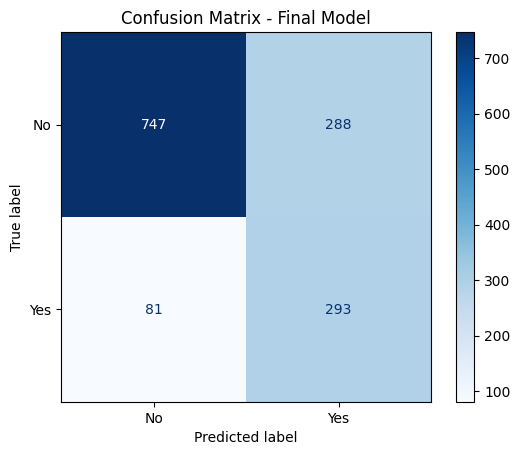

Confusion matrix:
[[747 288]
 [ 81 293]]


In [4]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=["No", "Yes"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Final Model")
plt.show()

print("Confusion matrix:")
print(cm)

The model correctly identified 293 of the 374 customers who churned, missing 81. This gives the churn class a recall of 78.3%.  
The trade-off is that 288 customers who did not churn were also flagged as likely churners. This is consistent with the project goal: I preferred to accept more unnecessary retention contacts rather than miss a large number of customers who were actually going to leave.

### What the error trade-off means operationally

At the chosen threshold the model flags **581 of the 1,409 test customers** for retention attention. That queue contains **293 genuine churners and 288 false alarms**, while **81 churners are missed**.

For a Head of Customer Service this turns the model question into a capacity question: *can the operation absorb roughly 581 proactive contacts for every 1,409 customers scored?* If not, the business should rank the flagged customers by model score and work the highest-risk cases first rather than pretending every positive prediction has the same urgency.

293 churners correctly caught ✅
81 churners missed ❌
288 non-churners incorrectly flagged as churn risks
747 non-churners correctly left alone

In [5]:
from sklearn.metrics import classification_report

# Per-class performance
print(classification_report(
    y_test,
    test_predictions,
    labels=["No", "Yes"]
))


# Build a dataframe so we can inspect mistakes
errors = X_test.copy()

errors["Actual"] = y_test
errors["Predicted"] = test_predictions
errors["Churn_probability"] = churn_probabilities


# False negatives:
# actually churned, but model predicted No
false_negatives = errors[
    (errors["Actual"] == "Yes") &
    (errors["Predicted"] == "No")
].sort_values(
    "Churn_probability",
    ascending=True
)


# False positives:
# did not churn, but model predicted Yes
false_positives = errors[
    (errors["Actual"] == "No") &
    (errors["Predicted"] == "Yes")
].sort_values(
    "Churn_probability",
    ascending=False
)


print("Most confident FALSE NEGATIVES:")
display(false_negatives.head(5))

print("\nMost confident FALSE POSITIVES:")
display(false_positives.head(5))

              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Most confident FALSE NEGATIVES:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual,Predicted,Churn_probability
4386,Male,0,Yes,Yes,55,Yes,No,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Bank transfer (automatic),57.55,3046.40,Yes,No,0.016601
4513,Female,1,Yes,Yes,72,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Two year,No,Credit card (automatic),92.45,6440.25,Yes,No,0.029178
2894,Female,0,No,No,48,Yes,No,DSL,Yes,No,Yes,Yes,No,No,One year,Yes,Credit card (automatic),60.35,2896.40,Yes,No,0.074380
5086,Male,0,No,No,45,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Electronic check,20.40,930.45,Yes,No,0.086728
3834,Female,0,Yes,Yes,57,Yes,No,DSL,Yes,No,No,No,Yes,Yes,One year,Yes,Bank transfer (automatic),70.10,3913.30,Yes,No,0.111929



Most confident FALSE POSITIVES:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual,Predicted,Churn_probability
3346,Female,1,No,No,2,Yes,Yes,Fiber optic,No,No,No,No,No,Yes,Month-to-month,Yes,Electronic check,84.05,186.05,No,Yes,0.920278
4039,Male,0,No,No,7,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,94.10,701.30,No,Yes,0.918038
935,Female,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,Yes,No,Month-to-month,Yes,Electronic check,83.25,308.05,No,Yes,0.915989
5019,Male,1,No,No,14,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.60,1273.30,No,Yes,0.911240
352,Female,1,No,No,7,Yes,No,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,89.15,574.35,No,Yes,0.906635


In [6]:
cols_to_show = [
    "tenure",
    "Contract",
    "InternetService",
    "MonthlyCharges",
    "TotalCharges",
    "PaymentMethod",
    "Actual",
    "Predicted",
    "Churn_probability"
]

print("Most confident FALSE NEGATIVES:")
display(false_negatives[cols_to_show].head(5))

print("\nMost confident FALSE POSITIVES:")
display(false_positives[cols_to_show].head(5))

Most confident FALSE NEGATIVES:


,tenure,Contract,InternetService,MonthlyCharges,TotalCharges,PaymentMethod,Actual,Predicted,Churn_probability
4386,55,Two year,DSL,57.55,3046.40,Bank transfer (automatic),Yes,No,0.016601
4513,72,Two year,DSL,92.45,6440.25,Credit card (automatic),Yes,No,0.029178
2894,48,One year,DSL,60.35,2896.40,Credit card (automatic),Yes,No,0.074380
5086,45,One year,No,20.40,930.45,Electronic check,Yes,No,0.086728
3834,57,One year,DSL,70.10,3913.30,Bank transfer (automatic),Yes,No,0.111929



Most confident FALSE POSITIVES:


,tenure,Contract,InternetService,MonthlyCharges,TotalCharges,PaymentMethod,Actual,Predicted,Churn_probability
3346,2,Month-to-month,Fiber optic,84.05,186.05,Electronic check,No,Yes,0.920278
4039,7,Month-to-month,Fiber optic,94.10,701.30,Electronic check,No,Yes,0.918038
935,4,Month-to-month,Fiber optic,83.25,308.05,Electronic check,No,Yes,0.915989
5019,14,Month-to-month,Fiber optic,95.60,1273.30,Electronic check,No,Yes,0.911240
352,7,Month-to-month,Fiber optic,89.15,574.35,Electronic check,No,Yes,0.906635


The most confident false negatives were mostly long-tenure customers on one- or two-year contracts, often using DSL and automatic payment methods. These customers looked very similar to customers who normally stay, so the model assigned them very low churn probabilities even though they eventually left.
The most confident false positives showed the opposite pattern: short tenure, month-to-month contracts, fibre optic internet, electronic check payments and relatively high monthly charges. These are all characteristics associated with higher churn in the training data, so the model was very confident they would leave even though they stayed.
This suggests the model has learned sensible overall patterns, but individual customers can still behave differently from customers with similar profiles.

---
## 4. What drives the predictions

Features pushing towards CHURN:


,Feature,Coefficient
17,categorical__InternetService_Fiber optic,0.715756
37,categorical__Contract_Month-to-month,0.662997
2,numeric__TotalCharges,0.474357
36,categorical__StreamingMovies_Yes,0.282577
33,categorical__StreamingTV_Yes,0.270039
44,categorical__PaymentMethod_Electronic check,0.244360
19,categorical__OnlineSecurity_No,0.205351
28,categorical__TechSupport_No,0.171101
15,categorical__MultipleLines_Yes,0.139709
41,categorical__PaperlessBilling_Yes,0.081673



Features pushing towards STAYING:


,Feature,Coefficient
0,numeric__tenure,-1.141091
39,categorical__Contract_Two year,-0.766446
1,numeric__MonthlyCharges,-0.677256
16,categorical__InternetService_DSL,-0.617657
20,categorical__OnlineSecurity_No internet service,-0.270347
23,categorical__OnlineBackup_No internet service,-0.270347
18,categorical__InternetService_No,-0.270347
26,categorical__DeviceProtection_No internet service,-0.270347
32,categorical__StreamingTV_No internet service,-0.270347
35,categorical__StreamingMovies_No internet service,-0.270347


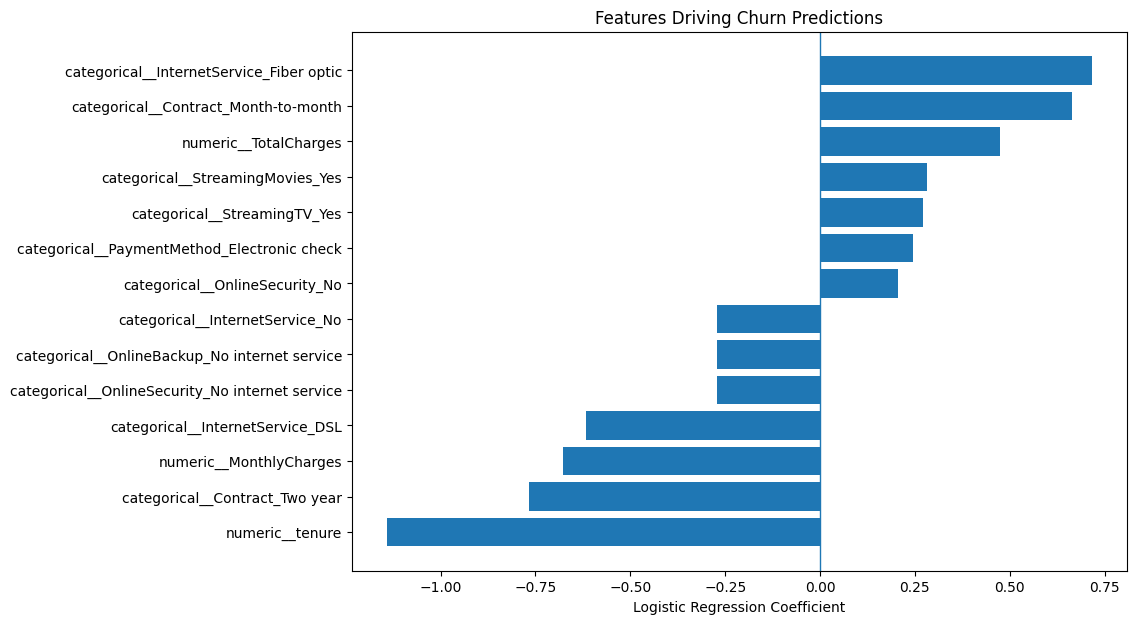

In [7]:
# Get the feature names after preprocessing
feature_names = final_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = final_model.named_steps[
    "model"
].coef_[0]

# Put them into a dataframe
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Largest positive coefficients = push prediction towards churn
top_positive = (
    feature_importance
    .sort_values("Coefficient", ascending=False)
    .head(10)
)

# Largest negative coefficients = push prediction towards staying
top_negative = (
    feature_importance
    .sort_values("Coefficient")
    .head(10)
)

print("Features pushing towards CHURN:")
display(top_positive)

print("\nFeatures pushing towards STAYING:")
display(top_negative)


# Plot strongest effects
strongest = pd.concat([
    top_negative.head(7),
    top_positive.head(7)
]).sort_values("Coefficient")

plt.figure(figsize=(10, 7))

plt.barh(
    strongest["Feature"],
    strongest["Coefficient"]
)

plt.axvline(0, linewidth=1)

plt.xlabel("Logistic Regression Coefficient")
plt.title("Features Driving Churn Predictions")

plt.show()

,Feature,Importance,Std
4,tenure,0.236497,0.014559
14,Contract,0.103877,0.014206
7,InternetService,0.038102,0.009524
17,MonthlyCharges,0.020856,0.009810
16,PaymentMethod,0.002674,0.005545
15,PaperlessBilling,0.000267,0.006322
2,Partner,-0.001203,0.001330
1,SeniorCitizen,-0.001604,0.002855
0,gender,-0.001872,0.001225
5,PhoneService,-0.002406,0.000802


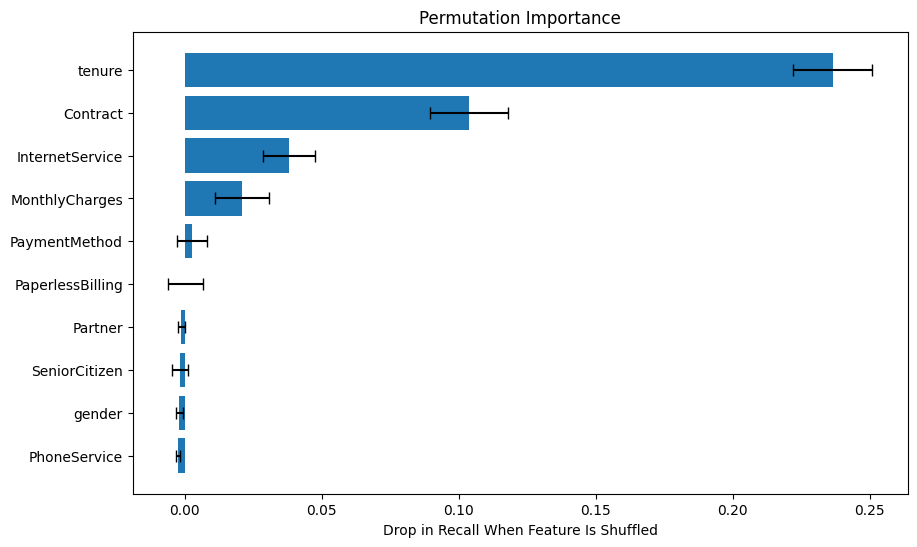

In [8]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, recall_score

# Use recall because that was our main project metric
recall_scorer = make_scorer(
    recall_score,
    pos_label="Yes"
)

# Measure permutation importance on the untouched test set
perm = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring=recall_scorer,
    n_repeats=20,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Put results into a dataframe
perm_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values("Importance", ascending=False)

display(perm_importance)

# Plot the 10 most important original features
top_perm = perm_importance.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))

plt.barh(
    top_perm["Feature"],
    top_perm["Importance"],
    xerr=top_perm["Std"],
    capsize=4
)

plt.xlabel("Drop in Recall When Feature Is Shuffled")
plt.title("Permutation Importance")

plt.show()

The strongest factors pushing predictions towards churn were fibre optic internet and month-to-month contracts. Electronic check payments, no online security, and some streaming services also increased the predicted likelihood of churn.
The strongest factors pushing predictions towards staying were longer tenure and two-year contracts. DSL internet was also associated with lower predicted churn.
The charge-related coefficients should be interpreted carefully because tenure, MonthlyCharges, TotalCharges, and several service choices are strongly related to each other. Logistic Regression coefficients show the effect of a feature while holding the others constant, so they should not be interpreted as proof that a feature causes churn.
From a business perspective, the clearest pattern is that newer customers on flexible month-to-month contracts appear to be the highest-risk group, while long-standing customers on longer contracts are considerably less likely to churn.

Permutation importance confirms that tenure is the most important original feature, followed by Contract and InternetService. Shuffling tenure caused the largest drop in recall, showing that the model relies heavily on how long a customer has been with the company when identifying churn risk.
Contract and InternetService also had a clear effect, which matches the earlier coefficient analysis: month-to-month contracts and fibre optic service were associated with higher churn risk.
MonthlyCharges had a smaller but still measurable influence. Most of the remaining variables had little or almost no effect on recall when shuffled, suggesting that the model relies much less heavily on them once the stronger features are already included.
This supports the earlier conclusion that customer tenure and contract structure are the clearest predictors of churn in this model.

---
## 5. Save, reload and predict

In [9]:
import joblib

# Make sure the models folder exists
MODELS.mkdir(parents=True, exist_ok=True)

model_path = MODELS / "telco_churn_model.joblib"

# Save BOTH the fitted pipeline and threshold
joblib.dump(
    {
        "model": final_model,
        "threshold": final_threshold
    },
    model_path
)

print("Saved to:", model_path)


# -------------------------
# RELOAD IT
# -------------------------

saved = joblib.load(model_path)

loaded_model = saved["model"]
loaded_threshold = saved["threshold"]

print("Model reloaded.")
print("Threshold:", loaded_threshold)


# -------------------------
# CREATE 3 EXAMPLE CUSTOMERS
# -------------------------

new_customers = pd.DataFrame([
    {
        "gender": "Female",
        "SeniorCitizen": 0,
        "Partner": "No",
        "Dependents": "No",
        "tenure": 3,
        "PhoneService": "Yes",
        "MultipleLines": "No",
        "InternetService": "Fiber optic",
        "OnlineSecurity": "No",
        "OnlineBackup": "No",
        "DeviceProtection": "No",
        "TechSupport": "No",
        "StreamingTV": "Yes",
        "StreamingMovies": "Yes",
        "Contract": "Month-to-month",
        "PaperlessBilling": "Yes",
        "PaymentMethod": "Electronic check",
        "MonthlyCharges": 95.00,
        "TotalCharges": 285.00
    },

    {
        "gender": "Male",
        "SeniorCitizen": 0,
        "Partner": "Yes",
        "Dependents": "Yes",
        "tenure": 60,
        "PhoneService": "Yes",
        "MultipleLines": "Yes",
        "InternetService": "DSL",
        "OnlineSecurity": "Yes",
        "OnlineBackup": "Yes",
        "DeviceProtection": "Yes",
        "TechSupport": "Yes",
        "StreamingTV": "No",
        "StreamingMovies": "No",
        "Contract": "Two year",
        "PaperlessBilling": "No",
        "PaymentMethod": "Bank transfer (automatic)",
        "MonthlyCharges": 60.00,
        "TotalCharges": 3600.00
    },

    {
        "gender": "Female",
        "SeniorCitizen": 0,
        "Partner": "Yes",
        "Dependents": "No",
        "tenure": 18,
        "PhoneService": "Yes",
        "MultipleLines": "Yes",
        "InternetService": "Fiber optic",
        "OnlineSecurity": "Yes",
        "OnlineBackup": "No",
        "DeviceProtection": "Yes",
        "TechSupport": "No",
        "StreamingTV": "Yes",
        "StreamingMovies": "No",
        "Contract": "One year",
        "PaperlessBilling": "Yes",
        "PaymentMethod": "Credit card (automatic)",
        "MonthlyCharges": 80.00,
        "TotalCharges": 1440.00
    }
])


# Get probabilities
new_probabilities = loaded_model.predict_proba(new_customers)

yes_index = list(
    loaded_model.named_steps["model"].classes_
).index("Yes")

new_churn_probabilities = new_probabilities[:, yes_index]

# Apply saved threshold
new_predictions = np.where(
    new_churn_probabilities >= loaded_threshold,
    "Yes",
    "No"
)

# Show results
demo_results = new_customers[
    ["tenure", "Contract", "InternetService", "PaymentMethod"]
].copy()

demo_results["Churn probability"] = new_churn_probabilities
demo_results["Predicted churn"] = new_predictions

display(demo_results)

Saved to: /mnt/data/project-2-ml-review/project-2-ml/models/telco_churn_model.joblib
Model reloaded.
Threshold: 0.5


,tenure,Contract,InternetService,PaymentMethod,Churn probability,Predicted churn
0,3,Month-to-month,Fiber optic,Electronic check,0.892318,Yes
1,60,Two year,DSL,Bank transfer (automatic),0.021015,No
2,18,One year,Fiber optic,Credit card (automatic),0.625585,Yes


The saved pipeline was successfully reloaded and used to score three new example customers. The predictions are consistent with the patterns found during EDA and model interpretation: short-tenure month-to-month customers with fibre optic service have higher predicted churn risk, while long-tenure customers on two-year contracts have much lower predicted risk.
This confirms that the saved model can be reused on new customer data without repeating the preprocessing manually.

---
## 6. Conclusions, recommendation and limitations

The final model is a tuned Logistic Regression classifier using `class_weight='balanced'` and a threshold of 0.50. It achieved **0.801 ± 0.038 cross-validated recall** and **0.783 recall on the untouched test set**, so performance remained stable on unseen customers.

It correctly identified **293 of 374 churners**, while also creating **288 false positives**. That trade-off fits the original business framing: missing a genuine churner was considered more costly than asking an agent to review a customer who ultimately stays.

The secondary question was also answered consistently. **Shorter tenure, month-to-month contracts and fibre optic service** are the clearest high-risk signals in this dataset, while **longer tenure and two-year contracts** push predictions towards staying.

### Recommendation

I would use the model as a **retention prioritisation tool**, not as an automatic decision-maker. A Head of Customer Service could use it to rank a customer list, set a daily contact capacity, and send the highest-risk cases to the retention team first. Agents should still use current customer context before deciding whether any intervention is appropriate.

### Limitations

The model only knows the variables available in this historical Telco dataset. It cannot see recent complaints, outages, satisfaction, competitor offers, new pricing or the content of support interactions. Its probability scores have also **not been separately calibrated**, so they are most defensible as a ranking signal rather than a promise that a customer has exactly a stated percentage chance of leaving.

In production I would monitor churn rate, recall, precision, false-positive workload and feature drift, and would retrain or review the model if those measures changed materially.